# SberAutoSubscription. Part 2: model for predicting the target action

Task: using the visit data (where the user came from, which device, which city) predict whether they will do a target action: leave a request, ask for a call and so on. The metric is ROC-AUC, the guide says to aim for about 0.65.

Here I compare models and look at which features matter. Training of the final model is in `pipeline.py`, the service is in `main.py` (how to run it is in README.md).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, precision_score, recall_score, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [2]:
sessions = pd.read_csv('data/ga_sessions.csv', dtype=str)
target = pd.read_csv('data/target.csv', dtype={'session_id': str})

# same as in the EDA, keep only the visits that have events
df = sessions.merge(target[['session_id', 'target']], on='session_id')
print(df.shape)
print('share of target visits:', round(df['target'].mean(), 4))

(1732266, 19)
share of target visits: 0.029


target.csv also has hits_count (how many events there were in the visit). I don't use it in the model: it's only known after the visit ends, and with it the model would basically be peeking at the answer. By the task, the service only gets the visit attributes: utm_*, device_*, geo_*, date, time and visit number.

## Feature preparation

What I do with the features (part of it was already in the EDA):
- '(not set)' is treated as missing;
- device_os is restored from the brand: Apple is iOS, other phones and tablets are Android;
- device_model is not used, it's almost all empty;
- from the date and time I take the hour and the day of week (in the EDA conversion depended on them);
- the screen resolution is split into width and height, strange values become missing;
- I add flags that a marketer can understand: organic traffic, social media ads, Moscow and Saint Petersburg.

The same function is in `pipeline.py`, so the service prepares the data in exactly the same way (only without the flags, which in the end didn't make it into the model, more on that below).

In [3]:
# social media sources, the list is from the project guide
SOCIAL = ['QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs',
          'IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw', 'gVRrcxiDQubJiljoTbGm']

CAT_FEATURES = ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
                'device_category', 'device_os', 'device_brand', 'device_browser', 'geo_country', 'geo_city']
NUM_FEATURES = ['visit_number', 'visit_hour', 'visit_weekday', 'screen_width', 'screen_height',
                'is_organic', 'is_social', 'is_moscow_spb']


def prepare(df):
    df = df.copy()
    df = df.replace('(not set)', np.nan)

    # device_os is often empty, but it can be restored from the brand
    df.loc[df['device_os'].isna() & (df['device_brand'] == 'Apple'), 'device_os'] = 'iOS'
    df.loc[df['device_os'].isna() & df['device_brand'].notna() & (df['device_brand'] != 'Apple')
           & df['device_category'].isin(['mobile', 'tablet']), 'device_os'] = 'Android'
    df[CAT_FEATURES] = df[CAT_FEATURES].fillna('other')

    df['visit_number'] = pd.to_numeric(df['visit_number'])
    df['visit_hour'] = pd.to_datetime(df['visit_time'], format='%H:%M:%S').dt.hour
    df['visit_weekday'] = pd.to_datetime(df['visit_date']).dt.day_of_week

    # the resolution comes as a string like '360x720', split it into width and height
    res = df['device_screen_resolution'].astype(str).str.split('x', expand=True).reindex(columns=[0, 1])
    df['screen_width'] = pd.to_numeric(res[0], errors='coerce')
    df['screen_height'] = pd.to_numeric(res[1], errors='coerce')
    bad = ((df['screen_width'] < 100) | (df['screen_height'] < 100)
           | (df['screen_width'] > 8000) | (df['screen_height'] > 8000))
    df.loc[bad, ['screen_width', 'screen_height']] = np.nan

    df['is_organic'] = df['utm_medium'].isin(['organic', 'referral', '(none)']).astype(int)
    df['is_social'] = df['utm_source'].isin(SOCIAL).astype(int)
    df['is_moscow_spb'] = df['geo_city'].isin(['Moscow', 'Saint Petersburg']).astype(int)
    return df[CAT_FEATURES + NUM_FEATURES]


X = prepare(df)
y = df['target'].values
X.head()

,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_browser,geo_country,geo_city,visit_number,visit_hour,visit_weekday,screen_width,screen_height,is_organic,is_social,is_moscow_spb
0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,Zlatoust,1,14,2,360.0,720.0,0,0,0
1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,Samsung Internet,Russia,Moscow,1,8,6,385.0,854.0,0,1,1
2,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,Krasnoyarsk,1,2,1,360.0,720.0,0,0,0
3,kjsLglQLzykiRbcDiGcD,cpc,other,NOBKLgtuvqYWkXQHeYWM,other,mobile,Android,Xiaomi,Chrome,Russia,Moscow,1,5,5,393.0,786.0,0,0,1
4,kjsLglQLzykiRbcDiGcD,cpc,other,other,other,mobile,Android,Xiaomi,Chrome,Russia,Moscow,2,5,5,393.0,786.0,0,0,1


In [4]:
X[CAT_FEATURES].nunique().sort_values()

device_category       3
device_os            13
utm_medium           55
device_browser       55
geo_country         159
device_brand        200
utm_source          281
utm_adcontent       281
utm_campaign        407
utm_keyword        1193
geo_city           2389
dtype: int64

In [5]:
for col in ['utm_keyword', 'geo_city', 'utm_campaign', 'device_brand']:
    counts = X[col].value_counts()
    frequent = counts[counts >= 100]
    print(f'{col}: values {len(counts)}, seen 100+ times: {len(frequent)}, '
          f'they cover {frequent.sum() / len(X):.1%} of visits')

utm_keyword: values 1193, seen 100+ times: 209, they cover 99.2% of visits
geo_city: values 2389, seen 100+ times: 330, they cover 98.9% of visits
utm_campaign: values 407, seen 100+ times: 188, they cover 99.7% of visits
device_brand: values 200, seen 100+ times: 47, they cover 99.9% of visits


Most values are rare. For example, out of 2389 cities only 330 appear at least 100 times, but they cover 98.9% of visits. Keywords are the same: 209 out of 1193 cover 99.2% of visits. So when encoding, I put all values that appear fewer than 100 times into one group. This way the model doesn't memorize single visits, and there are far fewer features.

## How much the features depend on each other

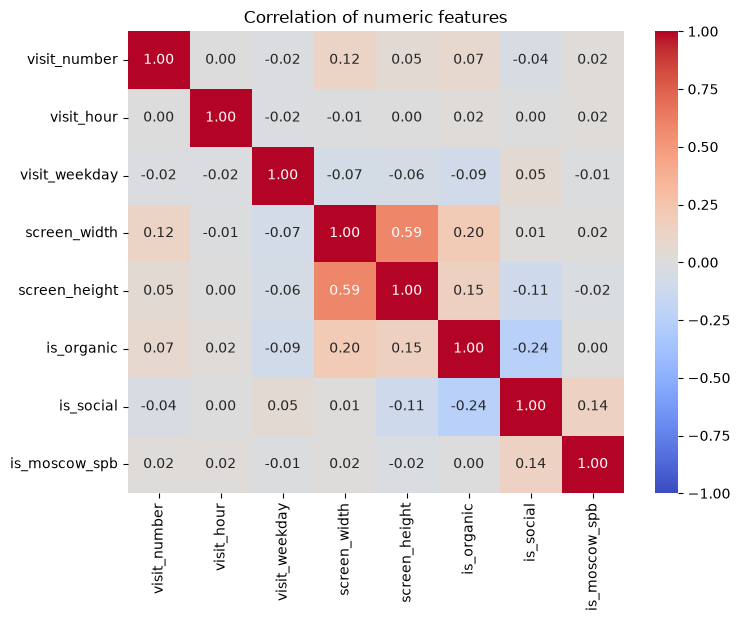

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(X[NUM_FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of numeric features')
plt.show()

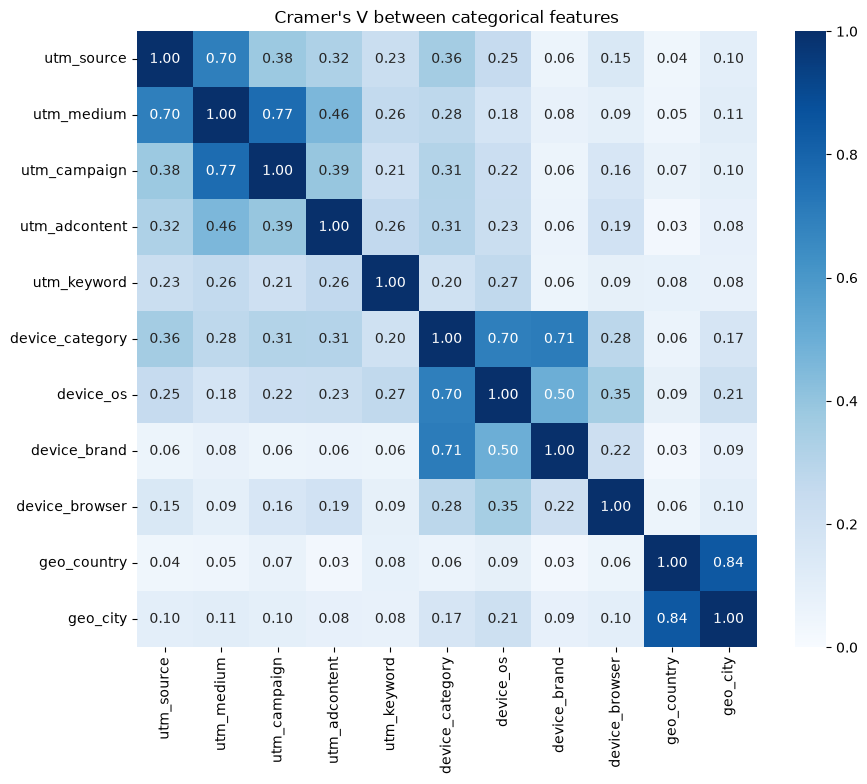

In [7]:
# correlation doesn't work for categorical features, so I use Cramer's V instead (from 0 to 1)
def cramers_v(a, b):
    table = pd.crosstab(a, b).values
    n = table.sum()
    expected = table.sum(axis=1, keepdims=True) * table.sum(axis=0, keepdims=True) / n
    chi2 = ((table - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / n / (min(table.shape) - 1))


sample = X.sample(300_000, random_state=42)
cramers = pd.DataFrame(index=CAT_FEATURES, columns=CAT_FEATURES, dtype=float)
for a in CAT_FEATURES:
    for b in CAT_FEATURES:
        cramers.loc[a, b] = 1.0 if a == b else cramers_v(sample[a], sample[b])

plt.figure(figsize=(10, 8))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title("Cramer's V between categorical features")
plt.show()

What I see:
- among the numeric features only screen width and height are noticeably related (0.59), the rest are almost not correlated;
- the flags is_organic, is_social and is_moscow_spb are weakly related to the numeric features, but they are fully computed from utm_medium, utm_source and geo_city, so they basically duplicate categorical features;
- among the categorical features utm_medium is strongly related to utm_campaign (0.77) and to utm_source (0.70): each campaign has its own traffic type. geo_country and geo_city (0.84) almost duplicate each other, because nearly all visits are from Russia. device_category is related to device_brand and device_os (0.70 and 0.71).

For logistic regression such dependencies are a problem, the coefficients become unstable. Trees in boosting handle this better, but I still check the extra features below with feature importance.

## Train, validation and test split

One client can have several visits, and they are very similar (same phone, same city). If visits of one client end up both in train and in test, the score will be too optimistic. So I split by client_id: 60% train, 20% validation (for choosing parameters and the threshold), 20% test (I look at it only once at the end).

In [8]:
groups = df['client_id'].values
train_idx, rest_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.4, random_state=42).split(X, y, groups))
valid_pos, test_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
                           .split(rest_idx, groups=groups[rest_idx]))
valid_idx, test_idx = rest_idx[valid_pos], rest_idx[test_pos]

X_train, y_train = X.iloc[train_idx], y[train_idx]
X_valid, y_valid = X.iloc[valid_idx], y[valid_idx]
X_test, y_test = X.iloc[test_idx], y[test_idx]

print('clients both in train and test:', len(set(groups[train_idx]) & set(groups[test_idx])))
pd.DataFrame({'visits': [len(y_train), len(y_valid), len(y_test)],
              'target share': [y_train.mean(), y_valid.mean(), y_test.mean()]},
             index=['train', 'valid', 'test']).round(4)

clients both in train and test: 0


,visits,target share
train,1038908,0.0288
valid,347870,0.0295
test,345488,0.0293


## Baseline

The simplest thing you can do without a model: calculate the conversion rate for each traffic source (utm_source) on the training set and assume that visits from a good source have a higher chance. The models will be compared with this.

In [9]:
results = {}

source_cr = pd.Series(y_train).groupby(X_train['utm_source'].values).mean()


def baseline_proba(X_):
    return X_['utm_source'].map(source_cr).fillna(y_train.mean()).values


results['baseline (utm_source conversion)'] = {
    'valid': roc_auc_score(y_valid, baseline_proba(X_valid)),
    'test': roc_auc_score(y_test, baseline_proba(X_test))}
results

{'baseline (utm_source conversion)': {'valid': 0.6226112970043807,
  'test': 0.6123233091919542}}

## Logistic regression

Categorical features are encoded with OneHotEncoder (rare values go into one column), numeric ones are filled with the median and scaled.

In [10]:
logreg = Pipeline([
    ('prep', ColumnTransformer([
        ('cat', OneHotEncoder(min_frequency=100, handle_unknown='infrequent_if_exist'), CAT_FEATURES),
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUM_FEATURES),
    ])),
    ('model', LogisticRegression(max_iter=1000)),
])

start = time.time()
logreg.fit(X_train, y_train)
print(f'training: {time.time() - start:.0f} s, features after encoding: {logreg[0].transform(X_train[:5]).shape[1]}')

results['logistic regression'] = {
    'valid': roc_auc_score(y_valid, logreg.predict_proba(X_valid)[:, 1]),
    'test': roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1])}
pd.DataFrame(results).T.round(4)

training: 6 s, features after encoding: 857


,valid,test
baseline (utm_source conversion),0.6226,0.6123
logistic regression,0.6816,0.6746


## Gradient boosting

I use HistGradientBoostingClassifier from sklearn. It trains fast on a million rows, works with categorical features by itself (no need for thousands of dummy columns), handles missing values and non-linear dependencies, for example conversion by hour or by visit number doesn't change in a straight line.

Categories are turned into numbers with OrdinalEncoder, rare ones (fewer than 100 visits) are merged into one, and values that weren't in the training data are treated as missing by the model.

In [11]:
def make_model(num_features=NUM_FEATURES, **params):
    encoder = ColumnTransformer([
        ('cat', OrdinalEncoder(min_frequency=100, max_categories=250,
                               handle_unknown='use_encoded_value', unknown_value=-1), CAT_FEATURES),
        ('num', 'passthrough', num_features),
    ], verbose_feature_names_out=False).set_output(transform='pandas')
    classifier = HistGradientBoostingClassifier(categorical_features=CAT_FEATURES, early_stopping=False,
                                                random_state=42, **params)
    return Pipeline([('encoder', encoder), ('classifier', classifier)])


# parameter search: a few options, I look at ROC-AUC on the validation set
param_grid = [
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 200, 'l2_regularization': 0.0},
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 500, 'l2_regularization': 1.0},
    {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 500, 'l2_regularization': 1.0},
    {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 127, 'min_samples_leaf': 1000, 'l2_regularization': 1.0},
    {'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'l2_regularization': 0.0},
    {'learning_rate': 0.1, 'max_iter': 400, 'max_leaf_nodes': 31, 'min_samples_leaf': 200, 'l2_regularization': 1.0},
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 0.0},
]

tuning = []
for params in param_grid:
    start = time.time()
    model = make_model(**params)
    model.fit(X_train, y_train)
    tuning.append({**params, 'roc_auc_valid': roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1]),
                   'time, s': round(time.time() - start)})

tuning = pd.DataFrame(tuning)
tuning.round(4)

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,roc_auc_valid,"time, s"
0,0.10,200,31,200,0.0,0.6929,11
1,0.10,200,63,500,1.0,0.6902,13
2,0.05,400,63,500,1.0,0.6900,21
3,0.05,400,127,1000,1.0,0.6845,27
4,0.10,300,15,200,0.0,0.6935,11
5,0.10,400,31,200,1.0,0.6889,14
6,0.10,200,31,50,0.0,0.6934,9


The difference between the options is small. The best ones are the models with small trees (15-31 leaves) and learning rate 0.1, while with big trees (127 leaves) the quality is worse: the signal in the data is weak, and big trees start fitting the noise. I take the best option: 15 leaves, 300 trees, learning rate 0.1. Each option trains in 10-30 seconds, so the model is easy to retrain.

In [12]:
best_params = param_grid[tuning['roc_auc_valid'].idxmax()]
print(best_params)

model = make_model(**best_params)
model.fit(X_train, y_train)
auc_full = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
print('ROC-AUC on validation:', round(auc_full, 4))

{'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'l2_regularization': 0.0}


ROC-AUC on validation: 0.6935


## What the new features add

A check: I train the same boosting only on the original categorical features and the visit number, without the hour, day of week, screen size and flags.

In [13]:
model_base = make_model(['visit_number'], **best_params)
model_base.fit(X_train, y_train)
print('without new features:', round(roc_auc_score(y_valid, model_base.predict_proba(X_valid)[:, 1]), 4))
print('with new features:   ', round(auc_full, 4))

without new features: 0.6924
with new features:    0.6935


The new features give a small gain: 0.6935 vs 0.6924. The model gets most of the information from the original utm tags, the city and the visit number. But the gain is there, and the features cost nothing in speed, so I keep them.

## Which features matter

I use permutation importance: shuffle the values of one feature and see how much ROC-AUC drops. The bigger the drop, the more the model relies on this feature.

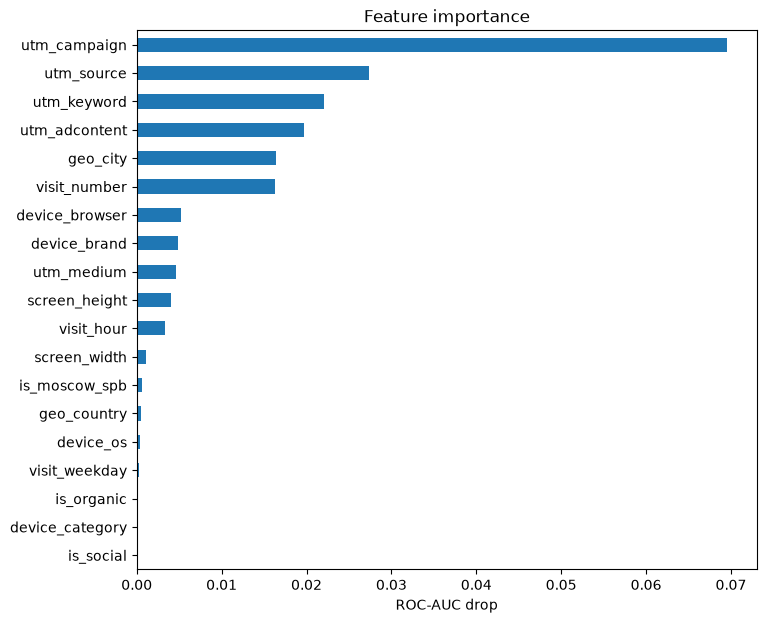

utm_campaign       0.0696
utm_source         0.0273
utm_keyword        0.0220
utm_adcontent      0.0196
geo_city           0.0164
visit_number       0.0162
device_browser     0.0053
device_brand       0.0049
utm_medium         0.0046
screen_height      0.0041
visit_hour         0.0033
screen_width       0.0010
is_moscow_spb      0.0006
geo_country        0.0005
device_os          0.0004
visit_weekday      0.0003
is_organic         0.0000
device_category    0.0000
is_social          0.0000
dtype: float64

In [14]:
# calculated on validation, I don't touch the test set yet
sample_idx = np.random.RandomState(42).choice(len(X_valid), 200_000, replace=False)
imp = permutation_importance(model, X_valid.iloc[sample_idx], y_valid[sample_idx], scoring='roc_auc',
                             n_repeats=3, random_state=42, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=X_valid.columns).sort_values()

plt.figure(figsize=(8, 7))
importance.plot(kind='barh')
plt.xlabel('ROC-AUC drop')
plt.title('Feature importance')
plt.show()
importance.sort_values(ascending=False).round(4)

The most important feature is utm_campaign: if it is shuffled, ROC-AUC drops by 0.07. Then come the other utm tags (source, keyword, ad content), the city and the visit number. So the chance of a target action depends first of all on which ad the person came from and how many times they have been on the site. Device and time of visit matter only a little.

The model doesn't need the flags is_organic, is_social and is_moscow_spb, their importance is about zero: it already knows the same thing from utm_medium, utm_source and geo_city. device_category is also close to zero, because the device type is clear from the brand, OS and screen size, but it's an original visit attribute, so I keep it. Let me check what happens if the flags are removed.

In [15]:
# the is_* flags are fully defined by utm_medium, utm_source and geo_city, boosting already sees this information
FINAL_NUM = ['visit_number', 'visit_hour', 'visit_weekday', 'screen_width', 'screen_height']
FINAL_FEATURES = CAT_FEATURES + FINAL_NUM

model = make_model(FINAL_NUM, **best_params)
model.fit(X_train[FINAL_FEATURES], y_train)
print('without flags:', round(roc_auc_score(y_valid, model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]), 4))
print('with flags:   ', round(auc_full, 4))

without flags: 0.6942
with flags:    0.6935


Without the flags the quality is even a bit higher (0.6942 vs 0.6935), so the final model doesn't have them. What's left are 11 categorical features and 5 numeric ones: visit number, hour, day of week, screen width and height. All of them are easy to explain: where the user came from, which device, which city, which visit it is and what time it was.

## Comparison on the test set

In [16]:
results['gradient boosting'] = {
    'valid': roc_auc_score(y_valid, model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]),
    'test': roc_auc_score(y_test, model.predict_proba(X_test[FINAL_FEATURES])[:, 1])}
pd.DataFrame(results).T.round(4)

,valid,test
baseline (utm_source conversion),0.6226,0.6123
logistic regression,0.6816,0.6746
gradient boosting,0.6942,0.6962


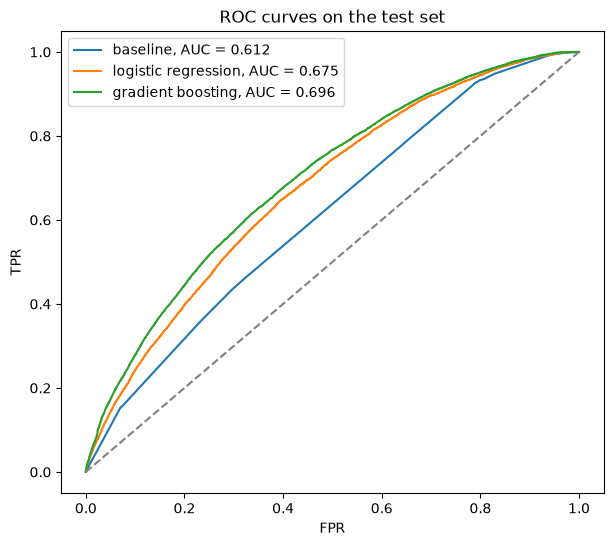

In [17]:
plt.figure(figsize=(7, 6))
for name, proba in [('baseline', baseline_proba(X_test)),
                    ('logistic regression', logreg.predict_proba(X_test)[:, 1]),
                    ('gradient boosting', model.predict_proba(X_test[FINAL_FEATURES])[:, 1])]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name}, AUC = {roc_auc_score(y_test, proba):.3f}')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curves on the test set')
plt.legend()
plt.show()

On the test set boosting gives ROC-AUC 0.696. This is above the 0.65 from the guide, above the traffic source baseline (0.612) and above logistic regression (0.675). The validation and test results are almost the same, so the model didn't overfit to the validation set I used for choosing the parameters.

## Threshold

The service has to return 0 or 1, and the model gives a probability. Only 3% of visits are targets, so the default threshold of 0.5 almost never fires. I choose the threshold on validation by the best F1.

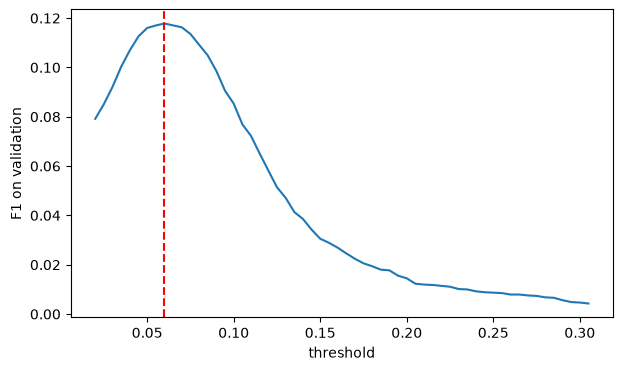

threshold: 0.06


In [18]:
valid_proba = model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]
thresholds = np.round(np.arange(0.02, 0.31, 0.005), 3)
f1s = [f1_score(y_valid, (valid_proba >= t).astype(int)) for t in thresholds]
threshold = thresholds[int(np.argmax(f1s))]

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1s)
plt.axvline(threshold, color='red', linestyle='--')
plt.xlabel('threshold')
plt.ylabel('F1 on validation')
plt.show()
print('threshold:', threshold)

precision: 0.085
recall:    0.223
F1:        0.123
share of visits where the model says 1: 0.077


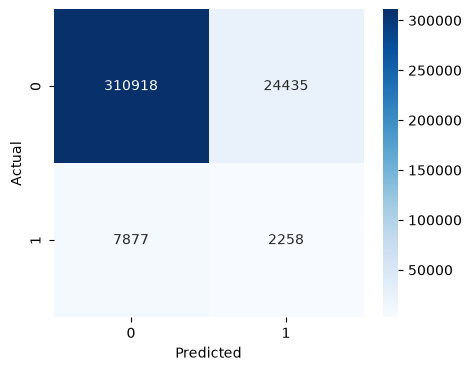

In [19]:
test_proba = model.predict_proba(X_test[FINAL_FEATURES])[:, 1]
test_pred = (test_proba >= threshold).astype(int)
print(f'precision: {precision_score(y_test, test_pred):.3f}')
print(f'recall:    {recall_score(y_test, test_pred):.3f}')
print(f'F1:        {f1_score(y_test, test_pred):.3f}')
print(f'share of visits where the model says 1: {test_pred.mean():.3f}')

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

With the threshold 0.06 the model says 1 for about 7.7% of visits. Of these, 8.5% do a target action (precision), which is almost 3 times the average conversion of 2.9%. At the same time the model finds 22% of all target visits (recall). It's hard to do much better from a single visit row: people from the same ad and with the same phones behave differently. If the business cares more about finding more target visits, the threshold can be lowered: recall goes up, precision goes down.

## How the model sees different groups of visits

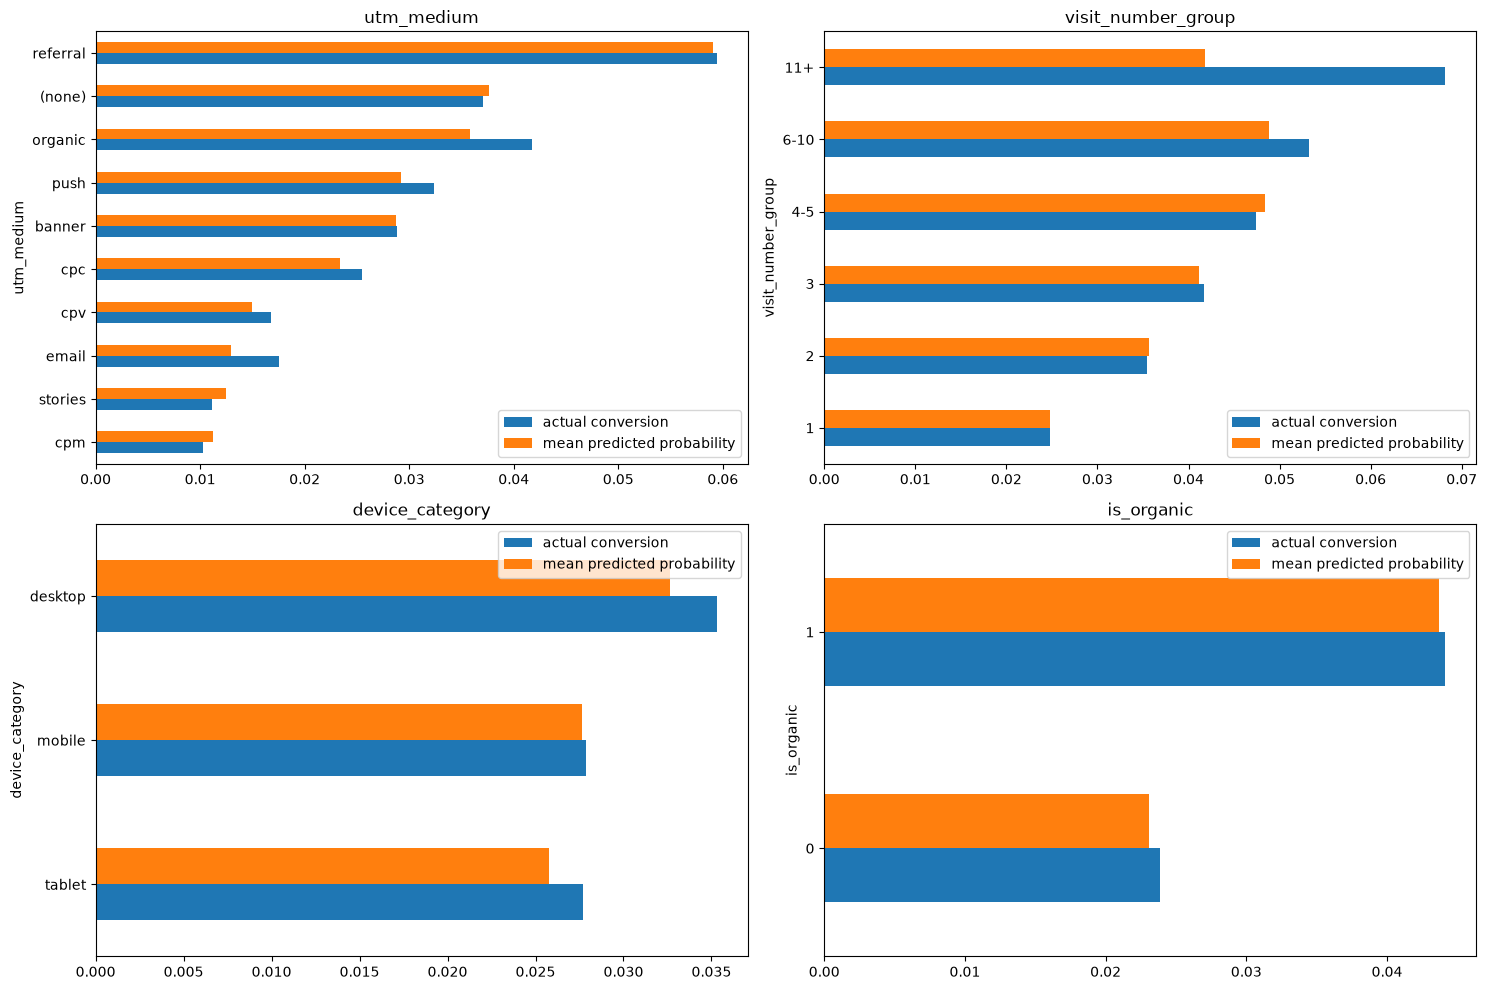

In [20]:
# how the predicted probability changes for features a marketer understands
X_show = X_test.copy()
X_show['target'] = y_test
X_show['proba'] = test_proba
X_show['visit_number_group'] = pd.cut(X_show['visit_number'], [0, 1, 2, 3, 5, 10, 10000],
                                      labels=['1', '2', '3', '4-5', '6-10', '11+'])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flatten(), ['utm_medium', 'visit_number_group', 'device_category', 'is_organic']):
    top = X_show[col].value_counts().index[:10]
    part = X_show[X_show[col].isin(top)].groupby(col, observed=True)[['target', 'proba']].mean()
    if col != 'visit_number_group':
        part = part.sort_values('proba')
    part.plot(kind='barh', ax=ax)
    ax.set_title(col)
    ax.legend(['actual conversion', 'mean predicted probability'], loc='best')
plt.tight_layout()
plt.show()

The mean predicted probability is almost the same as the actual conversion in each group, so the model not only ranks visits correctly but also gives realistic probabilities. What this tells a marketer:
- referrals from other sites convert best (referral, about 6%), and organic traffic in general too (4.4% vs 2.4% for paid);
- display ads cpm and stories are the worst, about 1%;
- the more times a person has already been on the site, the higher the chance of a request: 2.5% on the first visit and about 5% from the fourth. So ads aimed at people who have already visited the site should pay off better than bringing in new people;
- desktop converts a bit better than phones and tablets.

For users with 11 or more visits the model underestimates the probability (4.2% vs 6.8%), there are few such visits and the model doesn't give them enough weight.

## Check on future data

The service will work on new visits, so I check how a model trained on visits before December predicts the December visits.

In [21]:
dates = pd.to_datetime(df['visit_date'])
before = (dates < '2021-12-01').values
model_time = make_model(FINAL_NUM, **best_params)
model_time.fit(X.loc[before, FINAL_FEATURES], y[before])
print('visits in December:', (~before).sum())
print('conversion before December:', round(y[before].mean(), 4), ' in December:', round(y[~before].mean(), 4))
print('model ROC-AUC on December:', round(roc_auc_score(y[~before], model_time.predict_proba(X.loc[~before, FINAL_FEATURES])[:, 1]), 4))

source_cr_time = pd.Series(y[before]).groupby(X.loc[before, 'utm_source'].values).mean()
baseline_dec = X.loc[~before, 'utm_source'].map(source_cr_time).fillna(y[before].mean())
print('baseline ROC-AUC on December:', round(roc_auc_score(y[~before], baseline_dec), 4))

# shares of the main sources before December and in December
pd.DataFrame({'before December': X.loc[before, 'utm_source'].value_counts(normalize=True),
              'December': X.loc[~before, 'utm_source'].value_counts(normalize=True)}).sort_values('December', ascending=False).head(5).round(3)

visits in December: 366245
conversion before December: 0.0315  in December: 0.0199


model ROC-AUC on December: 0.6383
baseline ROC-AUC on December: 0.5442


,before December,December
utm_source,,
ZpYIoDJMcFzVoPFsHGJL,0.256,0.554
MvfHsxITijuriZxsqZqt,0.098,0.116
kjsLglQLzykiRbcDiGcD,0.160,0.073
fDLlAcSmythWSCVMvqvL,0.186,0.064
BHcvLfOaCWvWTykYqHVe,0.071,0.037


If the model is trained on visits before December and checked on December, ROC-AUC is 0.638, noticeably lower than with the random split by clients (0.696). The reason is that the traffic changed in December: the share of the main source grew from 26% to 55%, and conversion dropped from 3.15% to 2%. The source baseline almost stops working on December (0.544), while the model stays at about 0.64. Conclusion: the model has to be retrained regularly on fresh data, for example once a month, when ad campaigns change.

## Speed

In the service the model gets a raw visit row, so I check the whole chain: feature preparation, encoding and boosting.

In [22]:
full_pipe = Pipeline([('prepare', FunctionTransformer(prepare))] + model.steps)
raw = sessions.sample(1000, random_state=1)

start = time.time()
for i in range(100):
    full_pipe.predict_proba(raw.iloc[[i]])
print(f'one visit: {(time.time() - start) / 100 * 1000:.1f} ms')

start = time.time()
full_pipe.predict_proba(raw)
print(f'1000 visits at once: {(time.time() - start) * 1000:.1f} ms')

one visit: 12.2 ms
1000 visits at once: 17.0 ms


## Conclusions

- The target action can be predicted from visit data: gradient boosting gives ROC-AUC 0.696 on a test set of clients the model hasn't seen. The 0.65 target from the guide is reached, the baseline (0.612) and logistic regression (0.675) are worse.
- The ad campaign and traffic source, the city and the visit number affect the result the most. Device and time of visit matter only a little.
- Many features are related to each other (utm_medium, utm_campaign and utm_source, country and city). The is_* flags fully duplicated categorical features, so I removed them.
- The service returns 1 if the probability is 0.06 or higher. Such visits convert almost 3 times more often than average.
- Predicting one visit together with data preparation takes about 12 ms, 1000 visits at once about 17 ms, so the 3 second limit is met with a big margin.
- Traffic changes in new data, so the model should be retrained regularly (`python pipeline.py`, training takes less than a minute).

The final model is trained in `pipeline.py` on all the data with the same parameters and threshold and saved to `model/sber_auto_pipe.pkl`. The service `main.py` takes a visit in the ga_sessions format and returns 0 or 1.